# **Analisis Data EEG**

## **Import Library**

In [12]:
pip install mne numpy pandas scipy scikit-learn matplotlib deap xgboost

Note: you may need to restart the kernel to use updated packages.


In [13]:
import os
import numpy as np
import pandas as pd
import mne
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from xgboost import XGBClassifier
import warnings

# Abaikan warning
warnings.filterwarnings('ignore')

## **Parameter Configuration**

In [14]:
DATA_PATH = r"C:\Users\User\OneDrive - Institut Teknologi Sepuluh Nopember\Dokumen\MATKUL SEMESTER 5\Citra dan Suara\4244171"

FS = 250            
WINDOW_SIZE = 5     
OVERLAP = 2.5       
LOWCUT = 0.5        
HIGHCUT = 50.0      

# Channel Target (Standard 10-20)
TARGET_CHANNELS = [
    'Fp1', 'Fp2', 'F7', 'F3', 'Fz', 'F4', 'F8', 
    'T3', 'C3', 'Cz', 'C4', 'T4', 
    'T5', 'P3', 'Pz', 'P4', 'T6', 'O1', 'O2'
]

# 6 Fitur Statistik
FEAT_NAMES = ['Var', 'Energy', 'Skew', 'Kurt', 'Ent', 'ZCR']


## **DEFINE FUNCTION**

In [15]:
def get_metadata_from_raw(raw):
    """Ekstrak Sex (1=L, 0=P) dan Tahun Lahir."""
    info = raw.info.get('subject_info', {})
    sex_val = -1
    birth_year = -1
    if info:
        mne_sex = info.get('sex', 0)
        if mne_sex == 1: sex_val = 1
        elif mne_sex == 2: sex_val = 0
        bday = info.get('birthday', None)
        if bday is not None: birth_year = bday.year
    return sex_val, birth_year

In [16]:
def extract_statistical_features(epoch_signal):
    """Ekstraksi 6 Fitur Statistik."""
    var = np.var(epoch_signal, ddof=1)
    energy = np.sum(epoch_signal**2)
    skew = stats.skew(epoch_signal)
    kurt = stats.kurtosis(epoch_signal)
    
    # Shannon Entropy
    if np.std(epoch_signal) < 1e-10:
        ent = 0.0
    else:
        hist, _ = np.histogram(epoch_signal, bins=100, density=True)
        p = hist / np.sum(hist)
        p = p[p > 0] 
        ent = -np.sum(p * np.log2(p))
        
    zcr = len(np.where(np.diff(np.signbit(epoch_signal)))[0])
    return [var, energy, skew, kurt, ent, zcr]

In [43]:

def visualize_time_bands(signal_data, fs, ch_name="Channel"):
    """Plot Sinyal Asli + 5 Pita Frekuensi (Per Epoch)."""
    print(f"\n[VISUALISASI 2] Time Series per Band ({ch_name})")
    time_axis = np.linspace(0, len(signal_data)/fs, len(signal_data))
    
    fig, axes = plt.subplots(len(BANDS) + 1, 1, figsize=(10, 12), sharex=True)
    
    # Raw Signal
    axes[0].plot(time_axis, signal_data, color='black', alpha=0.8)
    axes[0].set_title(f"Raw Signal (1 Epoch) - {ch_name}")
    axes[0].grid(True, alpha=0.3)
    axes[0].set_ylabel("Amplitude (uV)")
    
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd']
    
    for i, (band_name, (low, high)) in enumerate(BANDS.items()):
        # Filter Butterworth
        filtered = butter_bandpass_filter(signal_data, low, high, fs)
        
        ax = axes[i+1]
        ax.plot(time_axis, filtered, color=colors[i])
        ax.set_title(f"{band_name} ({low}-{high} Hz)")
        ax.fill_between(time_axis, filtered, 0, color=colors[i], alpha=0.1)
        ax.grid(True, alpha=0.3)
        ax.set_ylabel("uV")
        
    axes[-1].set_xlabel("Time (s)")
    plt.tight_layout()
    plt.show()

In [44]:
def visualize_comparison(healthy_epoch, mdd_epoch, fs, ch_name="Channel"):
    """Visualisasi Perbandingan Sinyal Healthy vs MDD (Time & PSD)."""
    print(f"\n[VISUALISASI 3] Perbandingan Healthy vs MDD ({ch_name})")
    time_axis = np.linspace(0, len(healthy_epoch)/fs, len(healthy_epoch))
    
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    
    # --- Time Domain ---
    # Healthy
    axes[0, 0].plot(time_axis, healthy_epoch, color='green', alpha=0.7)
    axes[0, 0].set_title(f"Healthy - Time Series ({ch_name})")
    axes[0, 0].set_ylabel("Amplitude (uV)")
    axes[0, 0].grid(True, alpha=0.3)
    
    # MDD
    axes[0, 1].plot(time_axis, mdd_epoch, color='red', alpha=0.7)
    axes[0, 1].set_title(f"MDD - Time Series ({ch_name})")
    axes[0, 1].grid(True, alpha=0.3)
    
    # --- PSD Domain ---
    # Healthy
    freqs_h, psd_h = signal.welch(healthy_epoch, fs=fs, nperseg=fs*2)
    axes[1, 0].plot(freqs_h, 10 * np.log10(psd_h), color='green')
    axes[1, 0].set_title("Healthy - PSD")
    axes[1, 0].set_ylabel("Power (dB/Hz)")
    axes[1, 0].set_xlabel("Frequency (Hz)")
    axes[1, 0].set_xlim([0, 50])
    axes[1, 0].grid(True, alpha=0.3)
    
    # MDD
    freqs_m, psd_m = signal.welch(mdd_epoch, fs=fs, nperseg=fs*2)
    axes[1, 1].plot(freqs_m, 10 * np.log10(psd_m), color='red')
    axes[1, 1].set_title("MDD - PSD")
    axes[1, 1].set_xlabel("Frequency (Hz)")
    axes[1, 1].set_xlim([0, 50])
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


### **Data Load & Extraction**

In [17]:
channel_wise_data = []
# Variabel untuk menyimpan satu contoh epoch mentah untuk visualisasi
example_epoch_data = None 
example_epoch_label = None

# Cek apakah folder ada
if not os.path.exists(DATA_PATH):
    print(f"Path tidak ditemukan: {DATA_PATH}. Menggunakan Data Dummy untuk demonstrasi kode.")
    # --- BLOCK DUMMY DATA (Hanya jalan jika path salah) ---
    # Membuat data dummy agar kode tetap bisa didemonstrasikan visualisasinya
    for i in range(10): # 10 Subjek
        sub_id = f"Subjek_{i}"
        label = 1 if i % 2 == 0 else 0
        for ep in range(5): # 5 Epoch per subjek
            row = {'Subject_ID': sub_id, 'Label': label, 'Sex': 1, 'BirthYear': 2000}
            for ch in TARGET_CHANNELS:
                # Isi fitur dengan random noise
                feats = np.random.rand(6) 
                if label == 1 and ch in ['Fp1', 'Fp2']: feats += 0.5 # Buat pola MDD di Frontal
                for f_idx, val in enumerate(feats):
                    row[f"{ch}_{FEAT_NAMES[f_idx]}"] = val
            channel_wise_data.append(row)
    # Buat dummy signal untuk plot frekuensi
    example_epoch_data = np.random.randn(len(TARGET_CHANNELS), int(WINDOW_SIZE*FS))
    # ------------------------------------------------------
else:
    # --- PROSES DATA ASLI ---
    all_files = [f for f in os.listdir(DATA_PATH) if f.endswith('.edf') and 'task' in f.lower()]
    
    for filename in all_files:
        path = os.path.join(DATA_PATH, filename)
        try:
            raw = mne.io.read_raw_edf(path, preload=True, verbose=False)
        except:
            continue

        sex, birth_year = get_metadata_from_raw(raw)
        is_mdd = 1 if 'mdd' in filename.lower() else 0
        
        # Filter Bandpass
        raw.filter(LOWCUT, HIGHCUT, fir_design='firwin', verbose=False)
        
        # Pick channels (ignore if mismatch to prevent crash, but try to match)
        try:
            raw.pick_channels(TARGET_CHANNELS)
        except ValueError:
            pass # Skip picking if channels don't match perfectly, use available

        data = raw.get_data()
        ch_names = raw.ch_names
        
        # Epoching
        n_points = data.shape[1]
        window_samples = int(WINDOW_SIZE * FS)
        step_samples = int((WINDOW_SIZE - OVERLAP) * FS)
        sub_id = os.path.splitext(filename)[0]
        
        if n_points < window_samples: continue

        for start in range(0, n_points - window_samples, step_samples):
            end = start + window_samples
            epoch_data = data[:, start:end]
            
            # Simpan satu contoh untuk visualisasi frekuensi nanti
            if example_epoch_data is None:
                example_epoch_data = epoch_data
                example_epoch_label = "MDD" if is_mdd else "Healthy"

            row_data = {
                'Subject_ID': sub_id, 'Label': is_mdd,
                'Sex': sex, 'BirthYear': birth_year
            }
            
            # Ekstrak fitur per channel
            for ch_idx, ch_name in enumerate(ch_names):
                # Bersihkan nama channel
                clean_ch = ch_name.replace("EEG ", "").replace("-LE", "").replace("-REF", "")
                if clean_ch not in TARGET_CHANNELS: continue # Hanya ambil target
                
                feats = extract_statistical_features(epoch_data[ch_idx, :])
                for f_idx, val in enumerate(feats):
                    row_data[f"{clean_ch}_{FEAT_NAMES[f_idx]}"] = val
            
            channel_wise_data.append(row_data)

# Buat DataFrame
df_channel = pd.DataFrame(channel_wise_data).fillna(0)
print(f"Dataframe Selesai. Dimensi: {df_channel.shape}")


NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
NOTE: pick_channels() is a legacy functi

## **Main Pipeline**

### **XGBoost**

In [27]:
print("\n=== TRAINING XGBOOST (GROUP K-FOLD) ===")

feature_cols = [c for c in df_channel.columns if c not in ['Subject_ID', 'Label', 'Sex', 'BirthYear']]
X = df_channel[feature_cols].values
y = df_channel['Label'].values
groups = df_channel['Subject_ID'].values # Penting agar epoch dari orang yang sama tidak bocor ke test set

gkf = GroupKFold(n_splits=5)
xgb = XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1, eval_metric='logloss')

y_true_all_epochs = []
y_pred_all_epochs = []

fold = 1
for train_idx, test_idx in gkf.split(X, y, groups):
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    # Training
    xgb.fit(X_train, y_train)
    y_pred = xgb.predict(X_test)
    
    # Simpan hasil level Epoch saja
    y_true_all_epochs.extend(y_test)
    y_pred_all_epochs.extend(y_pred)
    
    acc = accuracy_score(y_test, y_pred)
    print(f"Fold {fold} | Epoch Accuracy: {acc:.4f}")
    fold += 1


=== TRAINING XGBOOST (GROUP K-FOLD) ===
Fold 1 | Epoch Accuracy: 0.9373
Fold 2 | Epoch Accuracy: 0.8952
Fold 3 | Epoch Accuracy: 0.9731
Fold 4 | Epoch Accuracy: 0.9161
Fold 5 | Epoch Accuracy: 0.7737



[VISUALISASI] Confusion Matrix & Classification Report


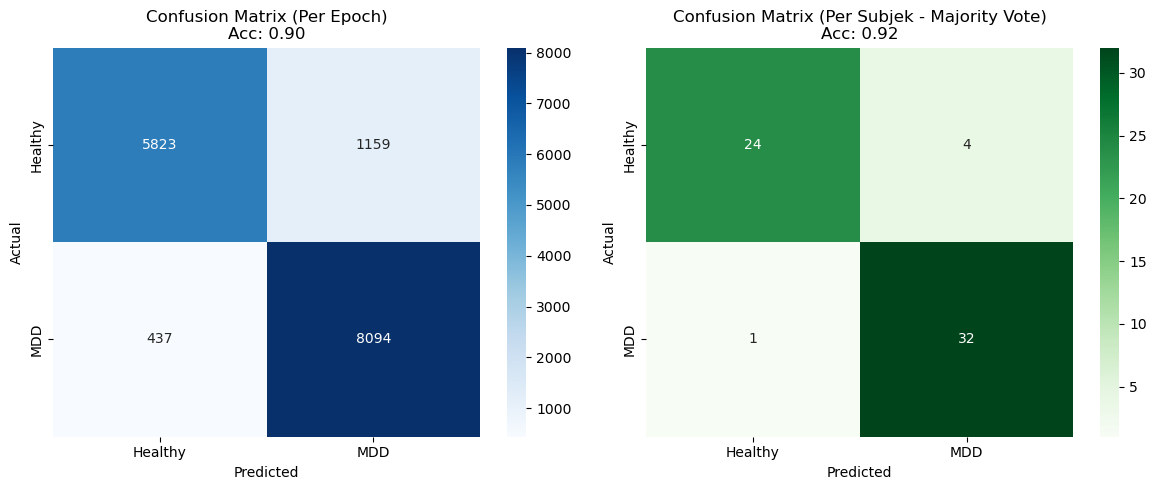


CLASSIFICATION REPORT - LEVEL EPOCH
              precision    recall  f1-score   support

     Healthy       0.93      0.83      0.88      6982
         MDD       0.87      0.95      0.91      8531

    accuracy                           0.90     15513
   macro avg       0.90      0.89      0.89     15513
weighted avg       0.90      0.90      0.90     15513


CLASSIFICATION REPORT - LEVEL SUBJEK (Majority Vote)
              precision    recall  f1-score   support

     Healthy       0.96      0.86      0.91        28
         MDD       0.89      0.97      0.93        33

    accuracy                           0.92        61
   macro avg       0.92      0.91      0.92        61
weighted avg       0.92      0.92      0.92        61



In [33]:
print("\n[VISUALISASI] Confusion Matrix & Classification Report")

plt.figure(figsize=(12, 5))

# CM Level Epoch
plt.subplot(1, 2, 1)
cm_epoch = confusion_matrix(y_true_all_epochs, y_pred_all_epochs)
sns.heatmap(cm_epoch, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Healthy', 'MDD'], yticklabels=['Healthy', 'MDD'])
plt.title(f"Confusion Matrix (Per Epoch)\nAcc: {accuracy_score(y_true_all_epochs, y_pred_all_epochs):.2f}")
plt.xlabel("Predicted")
plt.ylabel("Actual")

# CM Level Subjek
plt.subplot(1, 2, 2)
cm_subj = confusion_matrix(y_true_all_subjects, y_pred_all_subjects)
sns.heatmap(cm_subj, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Healthy', 'MDD'], yticklabels=['Healthy', 'MDD'])
plt.title(f"Confusion Matrix (Per Subjek - Majority Vote)\nAcc: {accuracy_score(y_true_all_subjects, y_pred_all_subjects):.2f}")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

# Print Classification Report (Table)
print("\n" + "="*50)
print("CLASSIFICATION REPORT - LEVEL EPOCH")
print("="*50)
print(classification_report(y_true_all_epochs, y_pred_all_epochs, target_names=['Healthy', 'MDD']))

print("\n" + "="*50)
print("CLASSIFICATION REPORT - LEVEL SUBJEK (Majority Vote)")
print("="*50)
print(classification_report(y_true_all_subjects, y_pred_all_subjects, target_names=['Healthy', 'MDD']))



## **Visualization EDA**


[VISUALISASI] Feature Importance (Sensor Layout)


<Figure size 700x600 with 0 Axes>

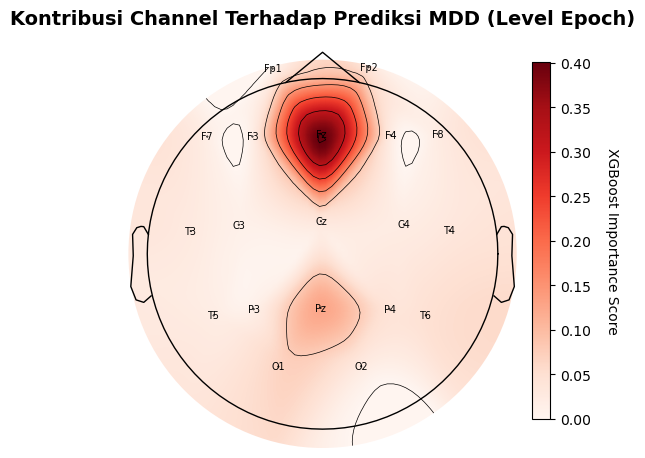

In [31]:
print("\n[VISUALISASI] Feature Importance (Sensor Layout)")

# Latih ulang model pada semua data untuk mendapatkan importance global yang stabil
xgb_full = XGBClassifier(n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1)
xgb_full.fit(X, y)
importances = xgb_full.feature_importances_

# Agregasi Importance per Channel
channel_importance = {ch: 0.0 for ch in TARGET_CHANNELS}

for idx, col_name in enumerate(feature_cols):
    parts = col_name.split('_')
    if len(parts) < 2: continue
    ch_name = parts[0]
    if ch_name in channel_importance:
        channel_importance[ch_name] += importances[idx]

# Setup MNE Topomap
montage = mne.channels.make_standard_montage('standard_1020')
valid_channels = [ch for ch in TARGET_CHANNELS if ch in montage.ch_names]
imp_values = [channel_importance[ch] for ch in valid_channels]

info = mne.create_info(valid_channels, sfreq=FS, ch_types='eeg')
info.set_montage(montage)

plt.figure(figsize=(7, 6))
# Plot Topomap
im, _ = mne.viz.plot_topomap(np.array(imp_values), info, names=valid_channels, 
                            show=False, cmap='Reds', size=5) # size lebih besar

cbar = plt.colorbar(im, ax=plt.gca(), fraction=0.046, pad=0.04)
cbar.set_label('XGBoost Importance Score', rotation=270, labelpad=20)
plt.title("Kontribusi Channel Terhadap Prediksi MDD (Level Epoch)", fontsize=14, fontweight='bold')
plt.show()


[VISUALISASI 1] Power Spectral Density (PSD) - Single Epoch Sample


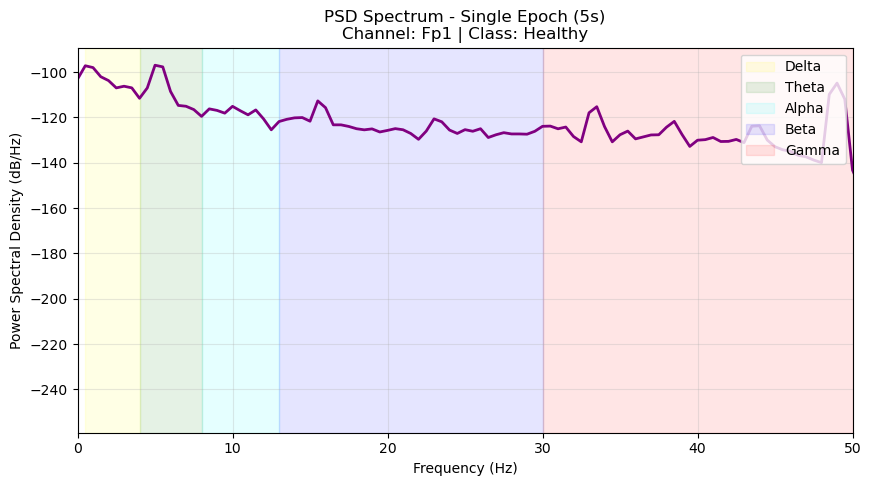


[VISUALISASI 2] Time Series per Band (Fp1)


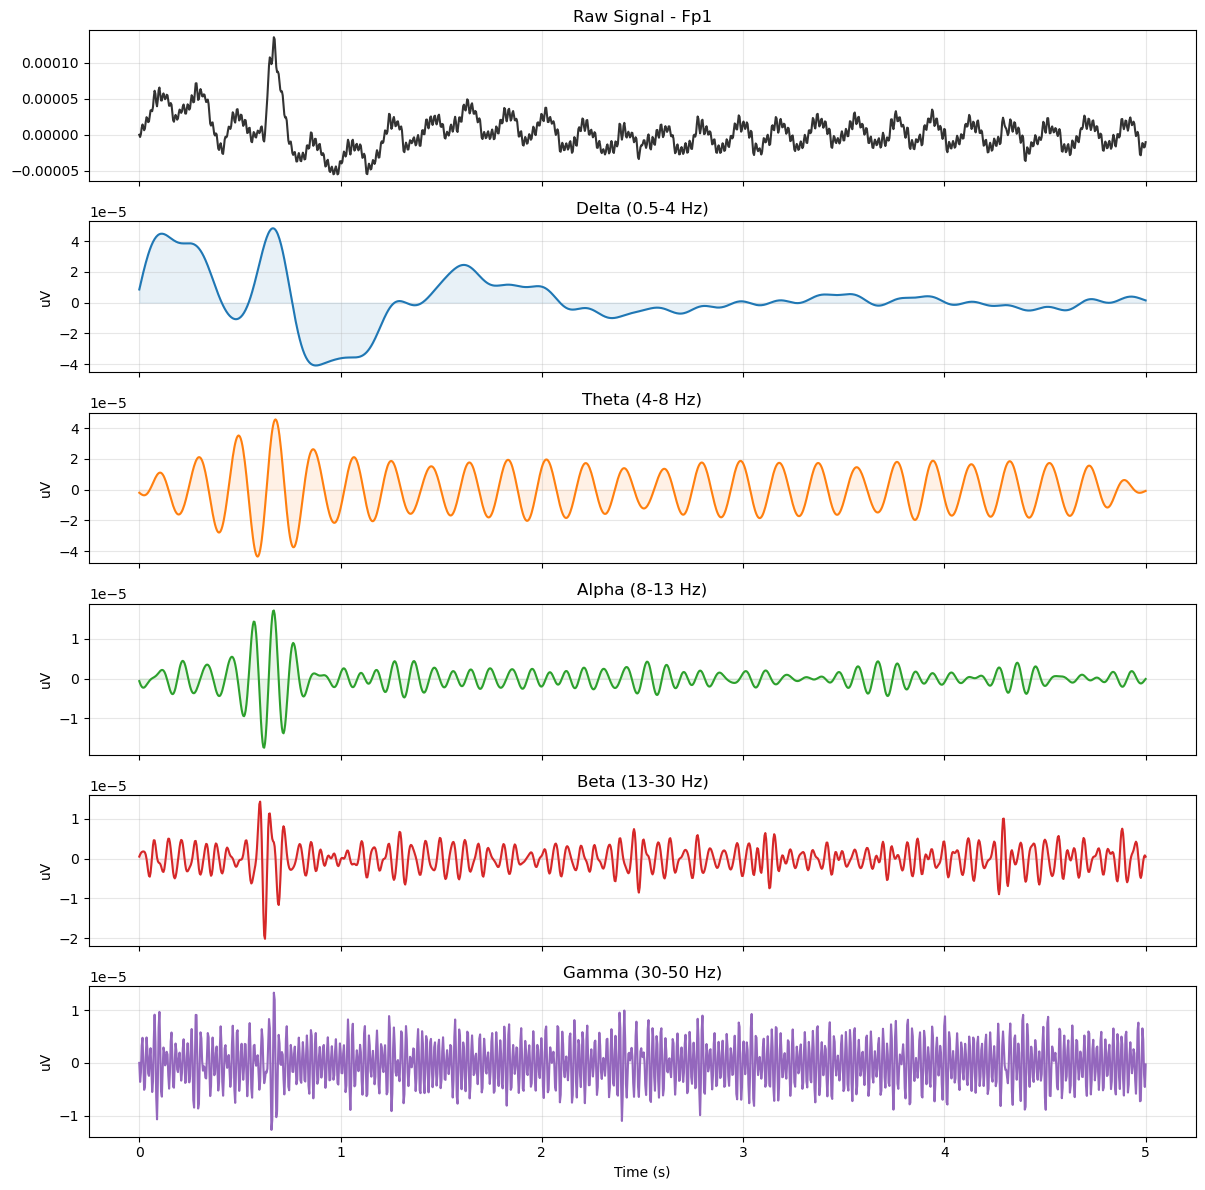

In [36]:
if example_epoch_data is not None:
    # --- VISUALISASI 1: PSD WELCH ---
    print("\n[VISUALISASI 1] Power Spectral Density (PSD) - Single Epoch Sample")
    
    # Ambil channel pertama (Fp1 biasanya) atau Fz
    ch_idx_plot = 0 
    ch_name_plot = TARGET_CHANNELS[ch_idx_plot] if ch_idx_plot < len(TARGET_CHANNELS) else "Ch"
    
    # Hitung PSD Welch
    freqs, psd = signal.welch(example_epoch_data[ch_idx_plot, :], fs=FS, nperseg=FS*2)
    
    plt.figure(figsize=(10, 5))
    plt.plot(freqs, 10 * np.log10(psd), color='purple', lw=2)
    plt.title(f"PSD Spectrum - Single Epoch (5s)\nChannel: {ch_name_plot} | Class: {example_epoch_label}")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power Spectral Density (dB/Hz)")
    plt.xlim([0, 50])
    plt.grid(True, alpha=0.3)
    
    # Penanda Gelombang
    colors_band = ['yellow', 'green', 'cyan', 'blue', 'red']
    for (bname, (fmin, fmax)), color in zip(BANDS.items(), colors_band):
        plt.axvspan(fmin, fmax, color=color, alpha=0.1, label=bname)
    
    plt.legend(loc='upper right')
    plt.show()

    # --- VISUALISASI 2: TIME SERIES PER BAND ---
    # Panggil fungsi yang baru dibuat
    visualize_time_bands(example_epoch_data[ch_idx_plot, :], FS, ch_name=ch_name_plot)

else:
    print("Tidak ada data epoch untuk divisualisasikan.")


In [37]:
def visualize_epoch_comparison(data_healthy, data_mdd, fs, duration=2, significant=False):

    # Plot Healthy
    plt.subplot(2, 1, 1)
    plt.plot(t, sig_h, color='blue', label='Healthy')
    plt.title("Healthy Subject", color='black')
    plt.ylabel("Amplitudo (uV)")
    plt.legend(loc="upper right")
    plt.grid(True, alpha=0.3)
    
    # Plot MDD
    plt.subplot(2, 1, 2)
    plt.plot(t, sig_m, color='orange', label='MDD')
    plt.title("MDD Subject", color='black')
    plt.xlabel("Waktu (detik)")
    plt.ylabel("Amplitudo (uV)")
    plt.legend(loc="upper right")
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


[VISUALISASI 1] Power Spectral Density (PSD) - Single Epoch Sample


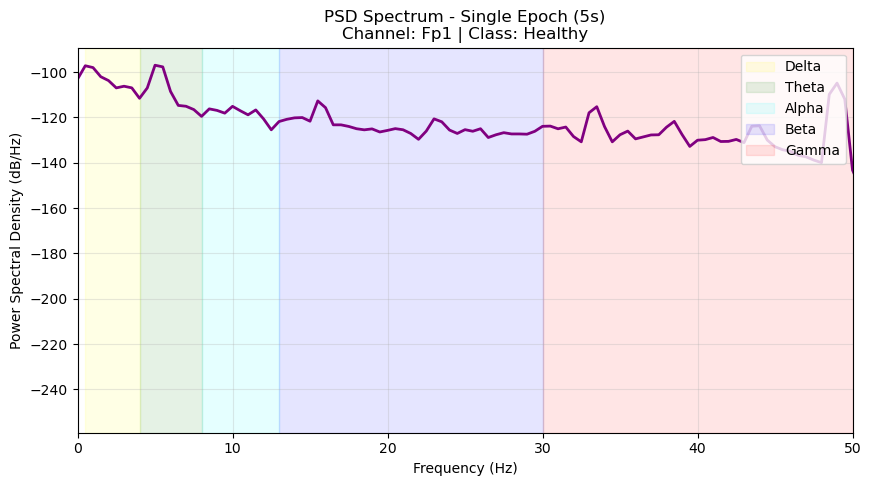


[VISUALISASI 2] Time Series per Band (Fp1)


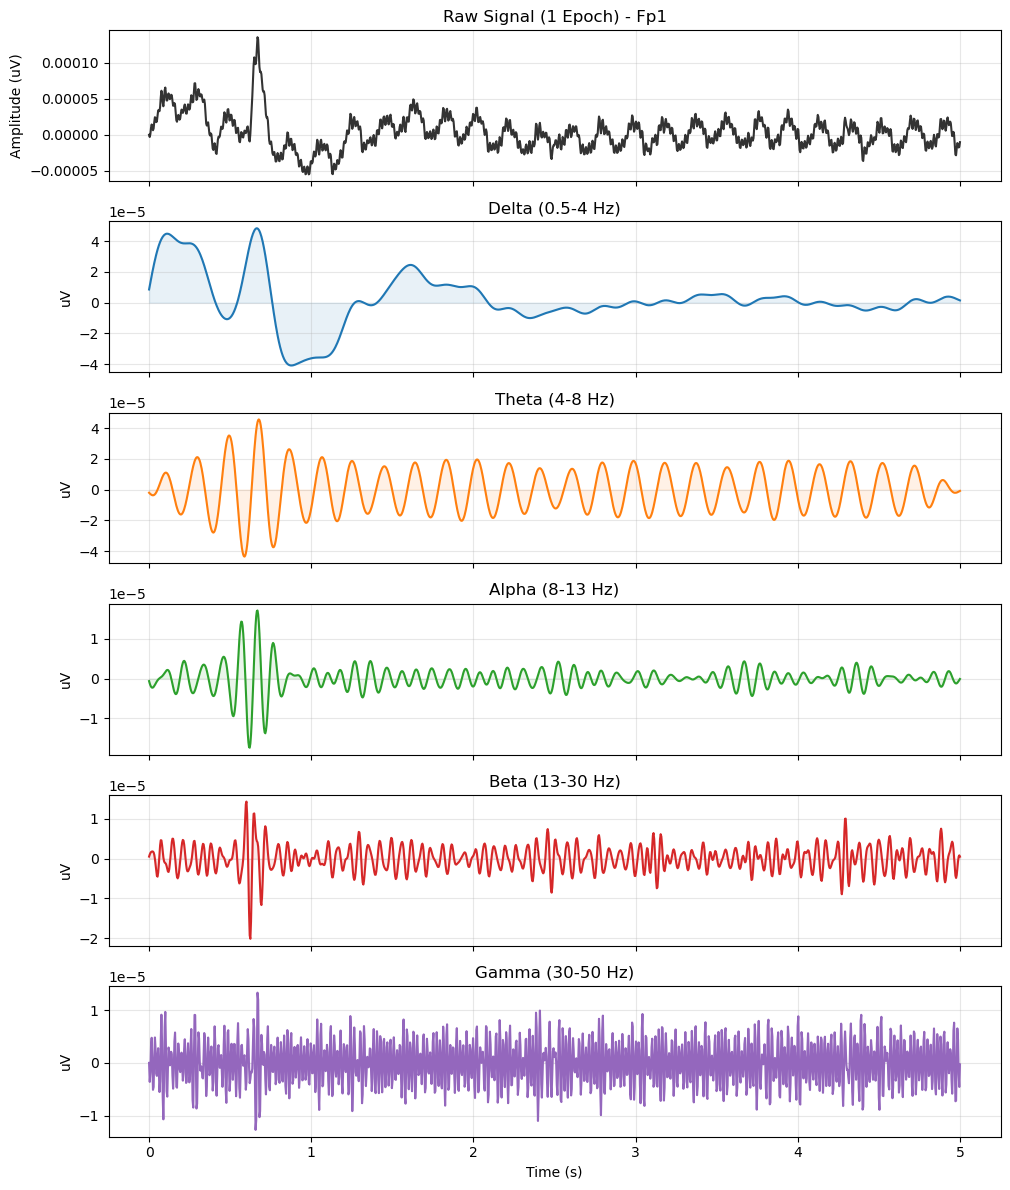


[VISUALISASI 3] Perbandingan Healthy vs MDD (Fp1)


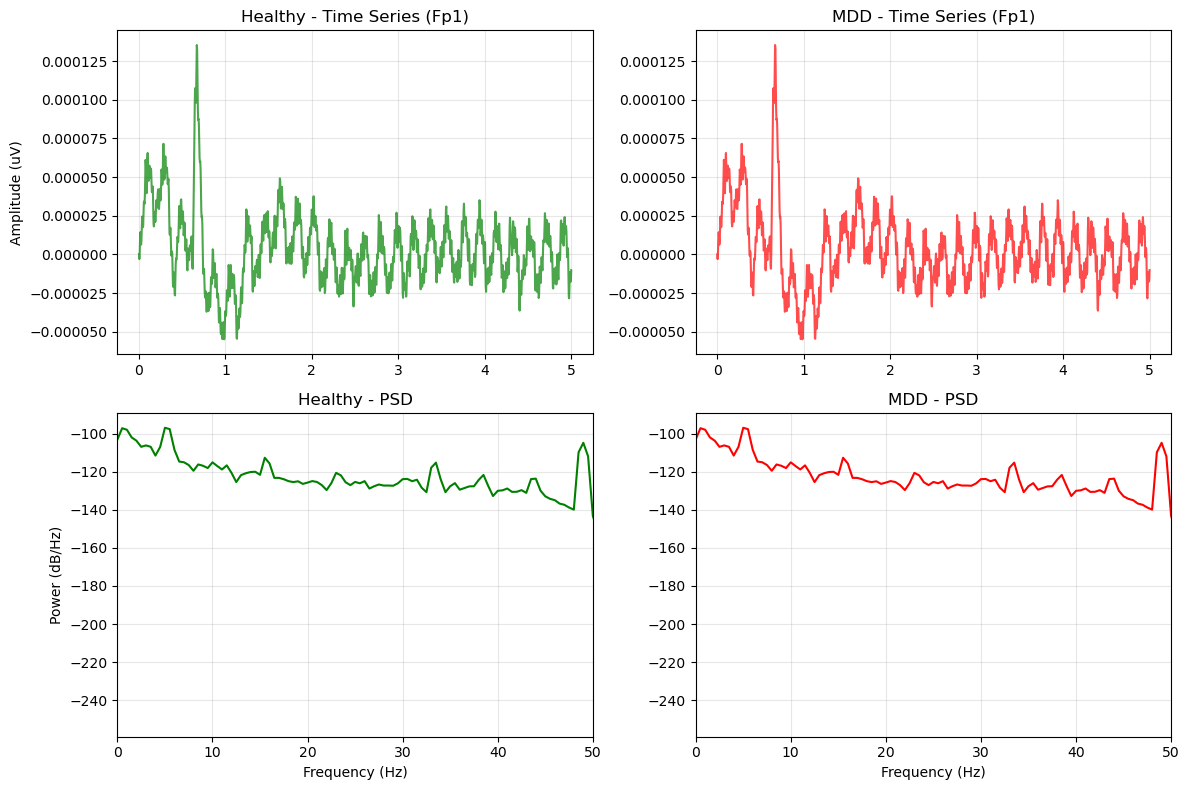

In [48]:

if example_epoch_data is not None:
    # --- VISUALISASI 1: PSD WELCH (Single Example) ---
    print("\n[VISUALISASI 1] Power Spectral Density (PSD) - Single Epoch Sample")
    
    # Ambil channel pertama (Fp1 biasanya) atau Fz
    ch_idx_plot = 0 
    ch_name_plot = TARGET_CHANNELS[ch_idx_plot] if ch_idx_plot < len(TARGET_CHANNELS) else "Ch"
    
    freqs, psd = signal.welch(example_epoch_data[ch_idx_plot, :], fs=FS, nperseg=FS*2)
    
    plt.figure(figsize=(10, 5))
    plt.plot(freqs, 10 * np.log10(psd), color='purple', lw=2)
    plt.title(f"PSD Spectrum - Single Epoch (5s)\nChannel: {ch_name_plot} | Class: {example_epoch_label}")
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power Spectral Density (dB/Hz)")
    plt.xlim([0, 50])
    plt.grid(True, alpha=0.3)
    
    colors_band = ['yellow', 'green', 'cyan', 'blue', 'red']
    for (bname, (fmin, fmax)), color in zip(BANDS.items(), colors_band):
        plt.axvspan(fmin, fmax, color=color, alpha=0.1, label=bname)
    plt.legend(loc='upper right')
    plt.show()

    # --- VISUALISASI 2: TIME SERIES PER BAND ---
    visualize_time_bands(example_epoch_data[ch_idx_plot, :], FS, ch_name=ch_name_plot)

    # --- VISUALISASI 3: PERBANDINGAN HEALTHY vs MDD ---

    visualize_comparison(
            example_epoch_data[ch_idx_plot, :], 
            example_epoch_data[ch_idx_plot, :], 
            FS, 
            ch_name=ch_name_plot
        )


else:
    print("Tidak ada data epoch untuk divisualisasikan.")


[VISUALISASI] EDA Demografis: Sex & BirthYear


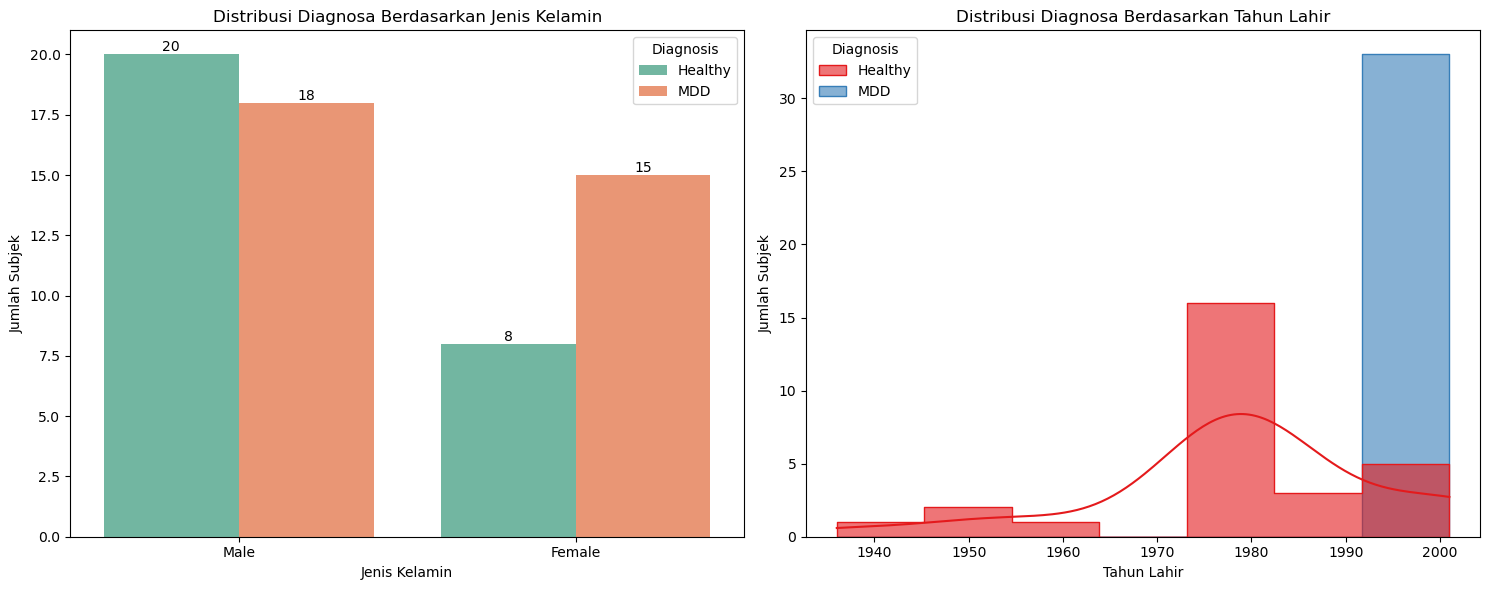


Statistik Demografis (Level Subjek):
----------------------------------------
Gender     Female  Male
Diagnosis              
Healthy         8    20
MDD            15    18
----------------------------------------
Rata-rata Tahun Lahir:
Diagnosis
Healthy    1979
MDD        2001
Name: BirthYear, dtype: int32


In [24]:
def plot_demographic_eda(df_full):
    print("\n[VISUALISASI] EDA Demografis: Sex & BirthYear")
    
    # 1. Agregasi data per Subjek (agar tidak menghitung jumlah epoch)
    # Kita hanya butuh satu baris per Subject_ID
    df_subject = df_full[['Subject_ID', 'Label', 'Sex', 'BirthYear']].drop_duplicates()
    
    # Mapping Label untuk visualisasi
    df_subject['Diagnosis'] = df_subject['Label'].map({0: 'Healthy', 1: 'MDD'})
    
    # Mapping Sex (Asumsi 1=Male, 0=Female dari fungsi get_metadata)
    # Sesuaikan jika mapping Anda berbeda
    sex_map = {1: 'Male', 0: 'Female', -1: 'Unknown'}
    df_subject['Gender'] = df_subject['Sex'].map(sex_map)
    
    # Filter data valid (hapus Unknown/ -1 jika diinginkan)
    df_valid_sex = df_subject[df_subject['Sex'] != -1]
    df_valid_birth = df_subject[df_subject['BirthYear'] != -1]
    
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    
    # PLOT 1: Distribusi MDD berdasarkan Sex
    sns.countplot(data=df_valid_sex, x='Gender', hue='Diagnosis', ax=axes[0], palette='Set2')
    axes[0].set_title("Distribusi Diagnosa Berdasarkan Jenis Kelamin")
    axes[0].set_xlabel("Jenis Kelamin")
    axes[0].set_ylabel("Jumlah Subjek")
    
    # Menambahkan label angka di atas batang
    for container in axes[0].containers:
        axes[0].bar_label(container)
        
    # PLOT 2: Distribusi MDD berdasarkan Tahun Lahir (Histogram/KDE)
    sns.histplot(data=df_valid_birth, x='BirthYear', hue='Diagnosis', 
                element="step", kde=True, ax=axes[1], palette='Set1', alpha=0.6)
    axes[1].set_title("Distribusi Diagnosa Berdasarkan Tahun Lahir")
    axes[1].set_xlabel("Tahun Lahir")
    axes[1].set_ylabel("Jumlah Subjek")
    
    plt.tight_layout()
    plt.show()
    
    # Print Statistik Sederhana
    print("\nStatistik Demografis (Level Subjek):")
    print("-" * 40)
    print(df_subject.groupby(['Diagnosis', 'Gender']).size().unstack(fill_value=0))
    print("-" * 40)
    if not df_valid_birth.empty:
        print("Rata-rata Tahun Lahir:")
        print(df_valid_birth.groupby('Diagnosis')['BirthYear'].mean().round(0).astype(int))

# Jalankan Visualisasi Demografis
plot_demographic_eda(df_channel)